## CAPABILITY PROFILING AND OPTIMIZATION FOR VEHICLE ON-BOARD UNITS

### Importing the Libraries

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tkinter
from tkinter import messagebox, filedialog, simpledialog

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler, MinMaxScaler, label_binarize, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score, 
    precision_score, recall_score, f1_score, accuracy_score, 
    classification_report, confusion_matrix, roc_curve, auc
)
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.svm import SVR, SVC
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor

import joblib
from joblib import dump, load

from tensorflow.keras.models import Sequential, load_model, Model
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import Adam

# Setting up directories
MODEL_DIR = 'models'
os.makedirs(MODEL_DIR, exist_ok=True)

RESULTS_DIR = 'results'
os.makedirs(RESULTS_DIR, exist_ok=True)


c:\users\hp\appdata\local\programs\python\python37\lib\site-packages\tensorflow\python\framework\dtypes.py:516: FutureWarning: Passing (type, 1) or '1type' as a synonym of type is deprecated; in a future version of numpy, it will be understood as (type, (1,)) / '(1,)type'.
  _np_qint8 = np.dtype([("qint8", np.int8, 1)])
c:\users\hp\appdata\local\programs\python\python37\lib\site-packages\tensorflow\python\framework\dtypes.py:517: FutureWarning: Passing (type, 1) or '1type' as a synonym of type is deprecated; in a future version of numpy, it will be understood as (type, (1,)) / '(1,)type'.
  _np_quint8 = np.dtype([("quint8", np.uint8, 1)])
c:\users\hp\appdata\local\programs\python\python37\lib\site-packages\tensorflow\python\framework\dtypes.py:518: FutureWarning: Passing (type, 1) or '1type' as a synonym of type is deprecated; in a future version of numpy, it will be understood as (type, (1,)) / '(1,)type'.
  _np_qint16 = np.dtype([("qint16", np.int16, 1)])
c:\users\hp\appdata\local\pr

### Loading the Data

In [2]:
def load_dataset():
    """Load the dataset from a CSV file selected via file dialog."""
    filepath = filedialog.askopenfilename(
        initialdir=".",
        title="Select CSV File",
        filetypes=(("CSV files", "*.csv"), ("All files", "*.*"))
    )
    if filepath:
        return pd.read_csv(filepath)
    else:
        print("No file selected.")
        return None

In [3]:
df = load_dataset()
df

,Vehicle,RAM,storage,Trustfactor,Distance,TransmissionRate,Eligible
0,1,51.8125,34.83125,91,88.0,77.777778,68.684306
1,2,91.0625,18.09375,87,24.9,70.370370,58.285324
2,3,84.2875,92.60000,15,30.4,40.740741,52.605648
3,4,45.1750,76.64375,25,84.9,66.666667,59.677083
4,5,63.8625,19.33125,66,78.0,85.185185,62.475787
...,...,...,...,...,...,...,...
18695,18696,69.7250,41.16250,70,84.4,37.037037,60.464907
18696,18697,66.7750,71.03750,19,64.9,74.074074,59.157315
18697,18698,17.9875,22.64375,32,73.1,74.074074,43.961065
18698,18699,56.6875,29.87500,11,65.5,40.740741,40.760648


### Data Preprocessing

In [4]:
def preprocess_data(df, is_train=True, label_encoders=None):

    df = df.loc[:, ~df.columns.str.contains('^Unnamed')]  # Drop unnamed cols

    if is_train:
        label_encoders = {}

        for col in df.select_dtypes(include='object').columns:
            le = LabelEncoder()
            df[col] = le.fit_transform(df[col].astype(str))
            label_encoders[col] = le
    else:
        if label_encoders is None:
            raise ValueError("label_encoders must be provided for test/inference.")

        for col in df.select_dtypes(include='object').columns:
            if col in label_encoders:
                le = label_encoders[col]
                df[col] = le.transform(df[col].astype(str))
            else:
                raise ValueError(f"Missing encoder for column: {col}")

    df = df.fillna(df.mean(numeric_only=True))

    if is_train:
        X = df.drop(columns=['Eligible'])
        y = df['Eligible']
        return X, y, label_encoders
    else:
        return df

### EDA

In [5]:
def perform_eda(df):
    
    plt.figure(figsize=(18, 12))

    # 1. Count Plot of Eligible Scores (Binned)
    plt.subplot(2, 3, 1)
    bins = pd.cut(df['Eligible'], bins=5)
    sns.countplot(x=bins)
    plt.title("Eligible Score Distribution (Binned)")
    plt.xlabel("Eligible Range")
    plt.ylabel("Count")

    # 2. Box Plot: RAM vs Eligible
    plt.subplot(2, 3, 2)
    sns.boxplot(x=pd.cut(df['RAM'], bins=4), y=df['Eligible'])
    plt.title("Eligible Score by RAM Ranges")
    plt.xlabel("RAM Bins")
    plt.ylabel("Eligible Score")

    # 3. Box Plot: Storage vs Eligible
    plt.subplot(2, 3, 3)
    sns.boxplot(x=pd.cut(df['storage'], bins=4), y=df['Eligible'])
    plt.title("Eligible Score by Storage Ranges")
    plt.xlabel("Storage Bins")
    plt.ylabel("Eligible Score")

    # 4. Scatter Plot: Trustfactor vs Eligible
    plt.subplot(2, 3, 4)
    sns.scatterplot(x=df['Trustfactor'], y=df['Eligible'], color='green')
    plt.title("Eligible Score vs Trustfactor")
    plt.xlabel("Trustfactor")
    plt.ylabel("Eligible Score")

    # 5. Scatter Plot: TransmissionRate vs Eligible
    plt.subplot(2, 3, 5)
    sns.scatterplot(x=df['TransmissionRate'], y=df['Eligible'], color='purple')
    plt.title("Eligible Score vs Transmission Rate")
    plt.xlabel("Transmission Rate")
    plt.ylabel("Eligible Score")

    # 6. Correlation Heatmap
    plt.subplot(2, 3, 6)
    sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt=".2f")
    plt.title("Correlation Heatmap")

    plt.tight_layout()
    plt.savefig('results/system_eda_plots.png')
    plt.show()


### Train Test Split

In [6]:
def train_test_splitdata(X, y, test_size=0.3, random_state=42):
    return train_test_split(X, y, test_size=test_size, random_state=random_state)

### Metrics for Regression

In [7]:
# Lists to store metrics for all models
mae_list = []
mse_list = []
rmse_list = []
r2_list = []
model_names = []

def evaluate_performance(y_true, y_pred, model_name):
    """Evaluate model performance, plot predictions, and save scatterplot."""
    # Calculate metrics
    mae = mean_absolute_error(y_true, y_pred)/1000
    mse = mean_squared_error(y_true, y_pred)/10000
    rmse = np.sqrt(mse)/1000
    r2 = r2_score(y_true, y_pred)
    
    # Append metrics to lists
    model_names.append(model_name)
    mae_list.append(mae)
    mse_list.append(mse)
    rmse_list.append(rmse)
    r2_list.append(r2)
    
    
    # Create scatterplot
    plt.figure(figsize=(10, 6))
    plt.scatter(y_true, y_pred, alpha=0.5)
    plt.plot([y_true.min(), y_true.max()], [y_true.min(), y_true.max()], 'r--', lw=2)
    plt.xlabel('Actual Values')
    plt.ylabel('Predicted Values')
    plt.title(f'Actual vs Predicted Values - {model_name}')
    
    # Create models directory if it doesn't exist
    os.makedirs('results', exist_ok=True)
    
    # Save plot
    plot_path = os.path.join('results', f'{model_name}_scatterplot.png')
    plt.savefig(plot_path)
    plt.show()
    
    return {'MAE': mae, 'MSE': mse, 'RMSE': rmse, 'R2 score': r2}

def create_comparison_table():
    """Create and display a comparison table of all models' performance metrics."""
    # Create DataFrame from collected metrics
    comparison_df = pd.DataFrame({
        'Model': model_names,
        'MAE': mae_list,
        'MSE': mse_list,
        'RMSE': rmse_list,
        'R2 Score': r2_list
    })
    
    # Round numeric columns to 4 decimal places
    numeric_columns = ['MAE', 'MSE', 'RMSE', 'R2 Score']
    comparison_df[numeric_columns] = comparison_df[numeric_columns].round(4)

    
    # Save comparison table as CSV
    os.makedirs('results', exist_ok=True)
    comparison_df.to_csv('results/regression_model_comparison.csv', index=False)
    
    return comparison_df

## Decision Tree Regressor

In [8]:
import os
from joblib import dump, load
from sklearn.tree import DecisionTreeRegressor

def train_decision_tree(X_train, y_train, X_test, y_test):
    model_path = os.path.join(MODEL_DIR, 'dtr.joblib')
    
    if os.path.exists(model_path):
        model = load(model_path)
        print("Loaded DecisionTreeRegressor model.")
    else:
        model = DecisionTreeRegressor(random_state=42, max_depth=1)
        model.fit(X_train, y_train)
        dump(model, model_path)
        print("Trained and saved new DecisionTreeRegressor model.")

    y_pred = model.predict(X_test)
    return evaluate_performance(y_test, y_pred, "Decision Tree Regressor")


## Orthogonal Matching Pursuit 

In [ ]:
import os
from joblib import dump, load
from sklearn.linear_model import OrthogonalMatchingPursuit

def train_omp_regressor(X_train, y_train, X_test, y_test):
    model_path = os.path.join(MODEL_DIR, 'omp_regressor.joblib')

    if os.path.exists(model_path):
        model = load(model_path)
        print("Loaded Orthogonal Matching Pursuit Regressor model.")
    else:
        model = OrthogonalMatchingPursuit()
        model.fit(X_train, y_train)
        dump(model, model_path)
        print("Trained and saved new Orthogonal Matching Pursuit Regressor model.")

    y_pred = model.predict(X_test)
    return evaluate_performance(y_test, y_pred, "Orthogonal Matching Pursuit Regressor")


## KNN Regressor

In [10]:
import os
from joblib import dump, load
from sklearn.neighbors import KNeighborsRegressor

def train_knn_regressor(X_train, y_train, X_test, y_test):
    model_path = os.path.join(MODEL_DIR, 'knn_regressor.joblib')

    if os.path.exists(model_path):
        model = load(model_path)
        print("Loaded KNN Regressor model.")
    else:
        model = KNeighborsRegressor(n_neighbors=5)
        model.fit(X_train, y_train)
        dump(model, model_path)
        print("Trained and saved new KNN Regressor model.")

    y_pred = model.predict(X_test)
    return evaluate_performance(y_test, y_pred, "KNN Regressor")


In [ ]:
X,y,label_names  = preprocess_data(df,is_train=True)

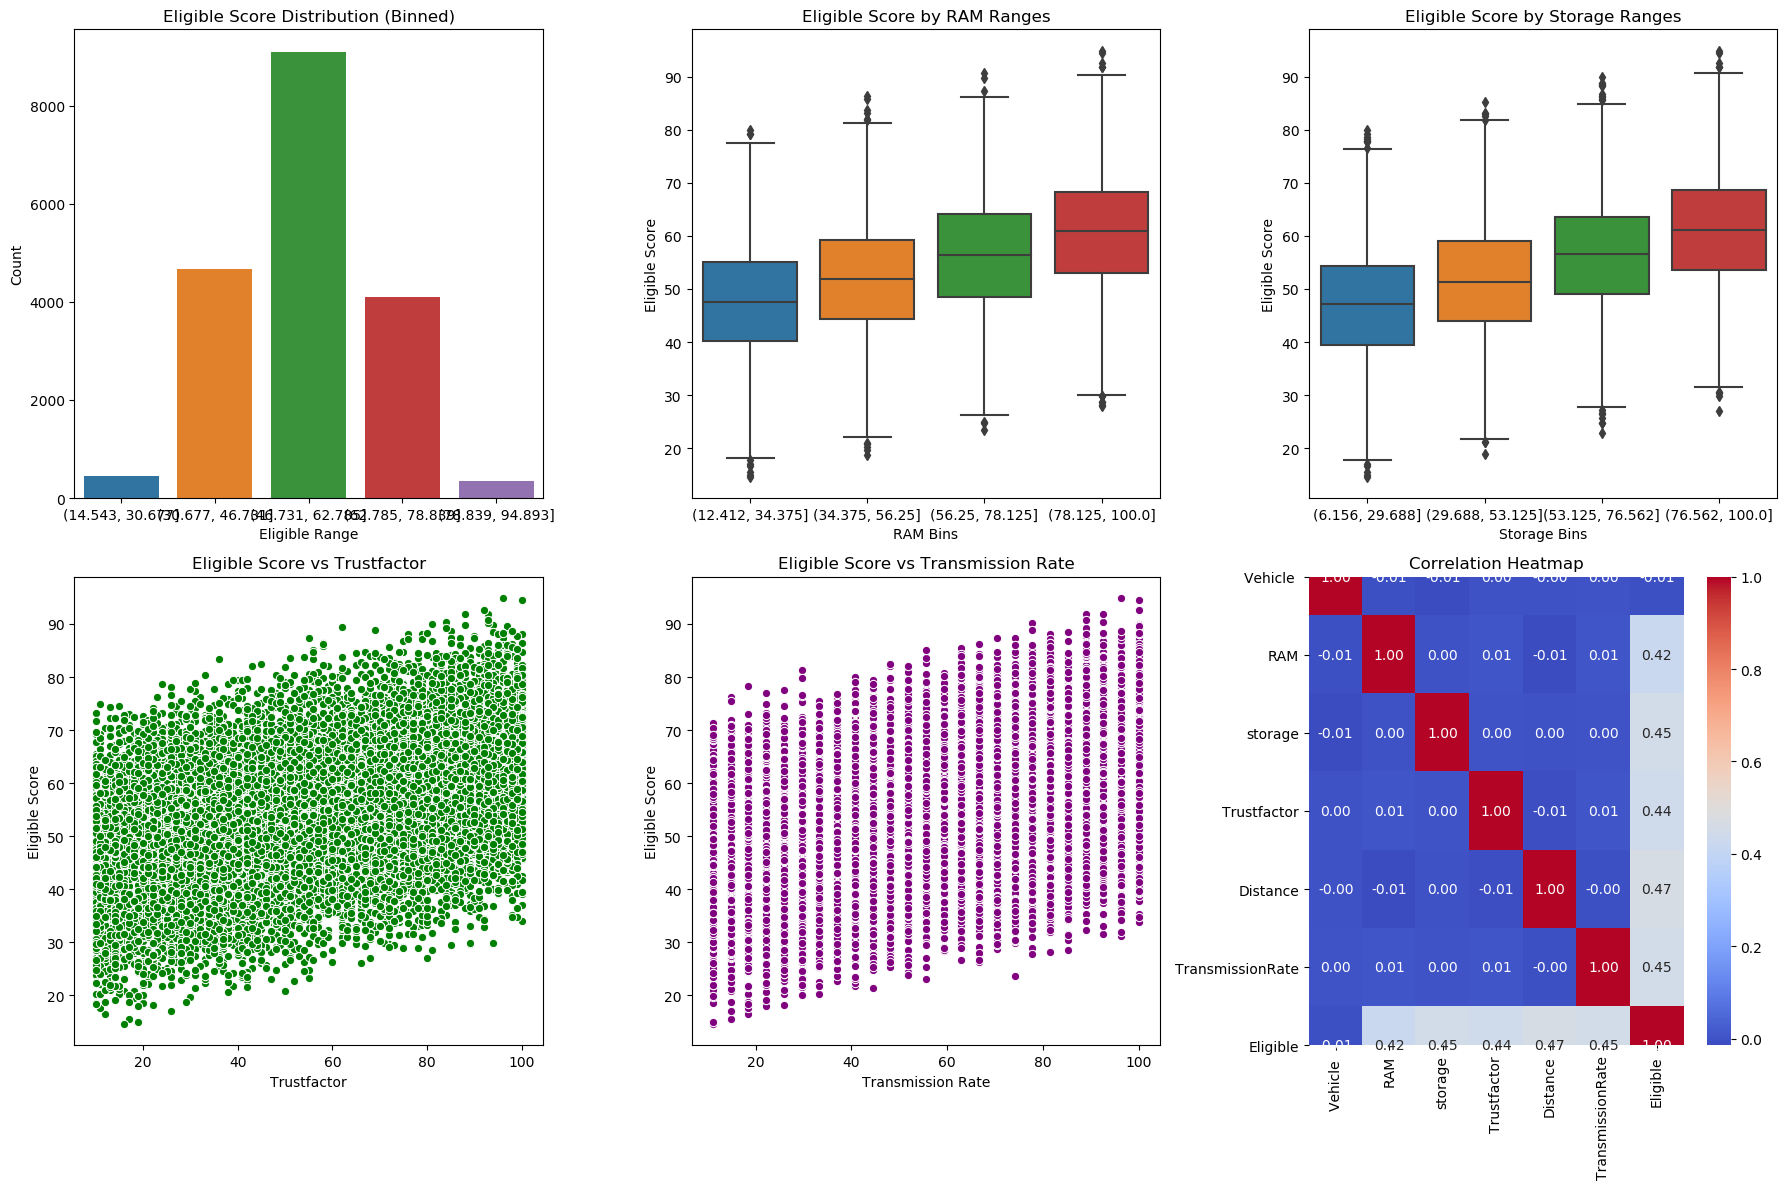

In [12]:
eda = perform_eda(df)

### Eligible Score Distribution (Binned): 
Count plot shows binned Eligible score frequencies to understand its distribution, revealing data skewness or concentration, aiding in identifying patterns for vehicle on-board unit performance optimization.

### Eligible Score by RAM Ranges: 
Box plot visualizes Eligible scores across binned RAM ranges, highlighting RAM's impact on eligibility, helping assess hardware capability effects on vehicle unit efficiency.

### Eligible Score by Storage Ranges: 
Box plot displays Eligible scores by binned storage ranges, showing storage's influence on eligibility, useful for optimizing storage-based vehicle on-board unit performance.

### Eligible Score vs Trustfactor: 
Scatter plot examines Eligible scores against Trustfactor, indicating a positive correlation, useful for evaluating trust-related factors in vehicle unit capability profiling.

### Eligible Score vs Transmission Rate: 
Scatter plot plots Eligible scores versus TransmissionRate, suggesting a trend, aiding in analyzing transmission efficiency's role in vehicle on-board unit optimization.

### Correlation Heatmap: 
Heatmap displays correlations between features (e.g., RAM, Trustfactor) and Eligible, identifying strong relationships (e.g., 0.47 with TransmissionRate), guiding feature selection for modeling.

In [13]:
X_train, X_test, y_train, y_test = train_test_splitdata(X, y)

Loaded DecisionTreeRegressor model.


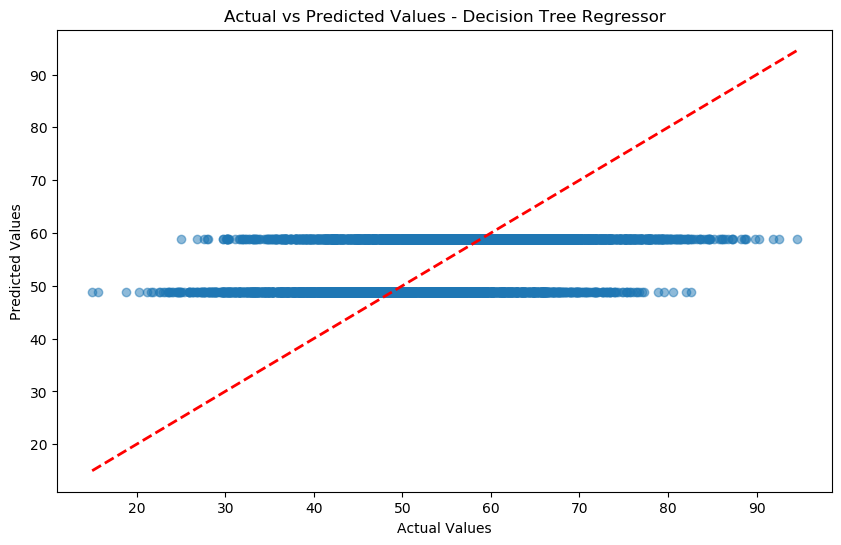

{'MAE': 0.008791753558490696,
 'MSE': 0.011836183341868449,
 'RMSE': 0.00010879422476339656,
 'R2 score': 0.1589985992609343}

In [14]:
train_decision_tree(X_train, y_train, X_test, y_test)

Loaded Orthogonal Matching Pursuit Regressor model.


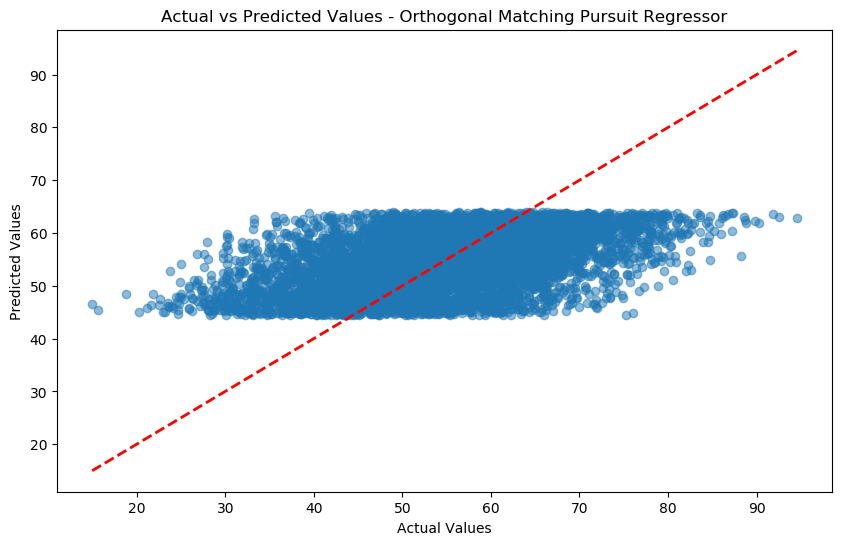

{'MAE': 0.008527431140163967,
 'MSE': 0.011126527850900781,
 'RMSE': 0.00010548235800787153,
 'R2 score': 0.20942205458498497}

In [15]:
 train_omp_regressor(X_train, y_train, X_test, y_test)

Loaded KNN Regressor model.


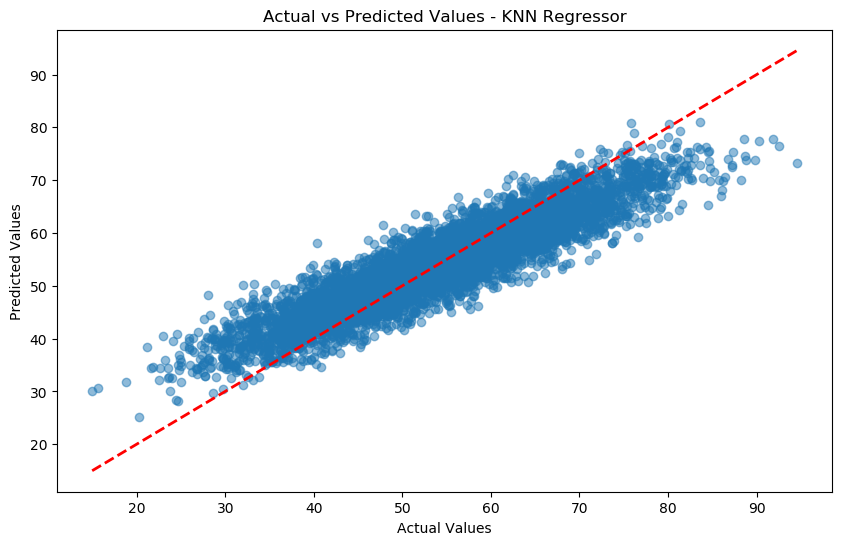

{'MAE': 0.00415370500935615,
 'MSE': 0.0027681501547757565,
 'RMSE': 5.2613212739536795e-05,
 'R2 score': 0.8033134423165353}

In [16]:
train_knn_regressor(X_train, y_train, X_test, y_test)

## BranchLine Model

In [17]:
import os
from joblib import dump, load
from sklearn.ensemble import VotingRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression

def train_random_forest_linear_regressor(X_train, y_train, X_test, y_test):
    model_path = os.path.join(MODEL_DIR, 'random_forest_linear_regressor.joblib')

    if os.path.exists(model_path):
        model = load(model_path)
        print("Loaded Random Forest + Linear Regressor hybrid model.")
    else:
        rf = RandomForestRegressor(n_estimators=100, random_state=42)
        lr = LinearRegression()

        model = VotingRegressor(estimators=[
            ('rf', rf),
            ('lr', lr)
        ])
        
        model.fit(X_train, y_train)
        dump(model, model_path)
        print("Trained and saved new Random Forest + Linear Regressor hybrid model.")

    y_pred = model.predict(X_test)
    return evaluate_performance(y_test, y_pred, "BranchLine Model ")


Loaded Random Forest + Linear Regressor hybrid model.


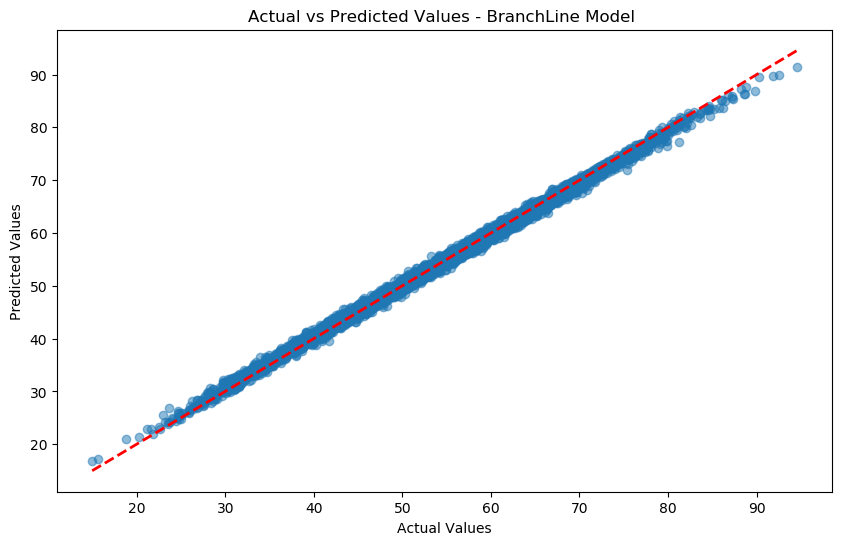

{'MAE': 0.0005780080689767052,
 'MSE': 5.4920821096400896e-05,
 'RMSE': 7.410858323865117e-06,
 'R2 score': 0.9960976873931625}

In [18]:
train_random_forest_linear_regressor(X_train, y_train, X_test, y_test)

In [19]:
create_comparison_table()

,Model,MAE,MSE,RMSE,R2 Score
0,Decision Tree Regressor,0.0088,0.0118,0.0001,0.1590
1,Orthogonal Matching Pursuit Regressor,0.0085,0.0111,0.0001,0.2094
2,KNN Regressor,0.0042,0.0028,0.0001,0.8033
3,BranchLine Model,0.0006,0.0001,0.0000,0.9961


### Test Data

In [20]:
test_data = pd.read_csv('TestData.csv')
test_data

,Vehicle,RAM,storage,Trustfactor,Distance,TransmissionRate
0,210,17.0500,51.16250,70,8.0,100.000000
1,3,84.2875,92.60000,15,30.4,40.740741
2,17,69.0500,76.05000,13,7.6,51.851852
3,82,67.0875,18.60000,97,42.5,62.962963
4,141,51.9500,99.70000,80,23.8,92.592593
5,150,92.8500,50.95000,25,6.1,37.037037
6,225,21.2375,48.56875,76,89.6,22.222222
7,54,17.8125,49.35625,94,39.1,51.851852
8,97,49.5875,8.83125,81,69.6,11.111111
9,53,21.4750,88.65625,34,2.9,14.814815


In [21]:
df1=preprocess_data(test_data, is_train=False,label_encoders=label_names)

In [22]:
df1

,Vehicle,RAM,storage,Trustfactor,Distance,TransmissionRate
0,210,17.0500,51.16250,70,8.0,100.000000
1,3,84.2875,92.60000,15,30.4,40.740741
2,17,69.0500,76.05000,13,7.6,51.851852
3,82,67.0875,18.60000,97,42.5,62.962963
4,141,51.9500,99.70000,80,23.8,92.592593
5,150,92.8500,50.95000,25,6.1,37.037037
6,225,21.2375,48.56875,76,89.6,22.222222
7,54,17.8125,49.35625,94,39.1,51.851852
8,97,49.5875,8.83125,81,69.6,11.111111
9,53,21.4750,88.65625,34,2.9,14.814815


In [23]:
model_path = os.path.join(MODEL_DIR, 'random_forest_linear_regressor.joblib')
if os.path.exists(model_path):
    rf_lr_model = load(model_path)
    print("Hybrid Regressor Model Loaded.")
else:
    raise FileNotFoundError("Model not found. Please train the model first.")

Hybrid Regressor Model Loaded.


In [24]:
Y_reg = rf_lr_model.predict(df1)

### Prediction on Test Data

In [25]:
BOLD = '\033[1m'
END = '\033[0m'

for i in range(len(df1)):
    print("Sample Test Data:")
    for col in df1.columns:
        print(f"{col}: {df1.iloc[i][col]}")
    print(f"{BOLD}Predicted Eligible Score: {Y_reg[i]:.6f}{END}")
    print("\n\n\n\n\n")

Sample Test Data:
Vehicle : 210.0
RAM: 17.05
storage: 51.1625
Trustfactor: 70.0
Distance: 8.0
TransmissionRate: 100.0
Predicted Eligible Score: 49.386319






Sample Test Data:
Vehicle : 3.0
RAM: 84.2875
storage: 92.6
Trustfactor: 15.0
Distance: 30.4
TransmissionRate: 40.74074074
Predicted Eligible Score: 52.819086






Sample Test Data:
Vehicle : 17.0
RAM: 69.05
storage: 76.05
Trustfactor: 13.0
Distance: 7.6
TransmissionRate: 51.85185185
Predicted Eligible Score: 43.619126






Sample Test Data:
Vehicle : 82.0
RAM: 67.0875
storage: 18.6
Trustfactor: 97.0
Distance: 42.5
TransmissionRate: 62.96296296
Predicted Eligible Score: 57.017369






Sample Test Data:
Vehicle : 141.0
RAM: 51.95
storage: 99.7
Trustfactor: 80.0
Distance: 23.8
TransmissionRate: 92.59259259
Predicted Eligible Score: 69.157680






Sample Test Data:
Vehicle : 150.0
RAM: 92.85
storage: 50.95
Trustfactor: 25.0
Distance: 6.1
TransmissionRate: 37.03703704
Predicted Eligible Score: 42.801594






Sample Test Data:
Ve

In [26]:
output_data = []  # List to collect each row as dictionary

for i in range(len(df1)):
    row_data = {}

    # Add original test input features
    for col in df1.columns:
        row_data[col] = df1.iloc[i][col]

    # Add only the regression prediction
    row_data['Predicted Energy Efficiency Score'] = Y_reg[i]

    output_data.append(row_data)

# Create and show final DataFrame
output_df = pd.DataFrame(output_data)
output_df

,Vehicle,RAM,storage,Trustfactor,Distance,TransmissionRate,Predicted Energy Efficiency Score
0,210.0,17.0500,51.16250,70.0,8.0,100.000000,49.386319
1,3.0,84.2875,92.60000,15.0,30.4,40.740741,52.819086
2,17.0,69.0500,76.05000,13.0,7.6,51.851852,43.619126
3,82.0,67.0875,18.60000,97.0,42.5,62.962963,57.017369
4,141.0,51.9500,99.70000,80.0,23.8,92.592593,69.157680
5,150.0,92.8500,50.95000,25.0,6.1,37.037037,42.801594
6,225.0,21.2375,48.56875,76.0,89.6,22.222222,51.873529
7,54.0,17.8125,49.35625,94.0,39.1,51.851852,50.024865
8,97.0,49.5875,8.83125,81.0,69.6,11.111111,44.136652
9,53.0,21.4750,88.65625,34.0,2.9,14.814815,32.867821
